# Parameter sweep recovery

Load a completed parameter sweep and draw per-parameter recovery diagnostics for each stimulus configuration.


In [1]:
from collections.abc import Sequence
from pathlib import Path
import csv
import json
import os
import sys
from typing import Any

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import arviz as az
from arviz_stats.ecdf_utils import ecdf_pit
from IPython.display import Markdown, display
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import xarray as xr

A4_PORTRAIT_INCHES = (8.27, 11.69)
A4_LANDSCAPE_INCHES = (11.69, 8.27)

DIAGNOSTICS_FIGURE_SIZE = A4_PORTRAIT_INCHES

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from coupling_sources.core.priors import CouplingPriors
from coupling_sources.utils.artifacts import Artifacts

In [2]:
def load_parameter_sweep(
    run_dir: Path | str,
    *,
    parameters: Sequence[str] | None = None,
    stimulus_columns: Sequence[str] | None = None,
) -> xr.Dataset:
    run_dir = Path(run_dir)
    parameter_names = tuple(parameters or CouplingPriors.parameter_sites())

    with (run_dir / "job_grid.csv").open(newline="") as file:
        rows = list(csv.DictReader(file))
    job_grid_columns = tuple(rows[0])

    stimulus_columns = tuple(
        column
        for column in (stimulus_columns or job_grid_columns)
        if column.startswith("stimuli_") and column != "stimuli_path"
    )
    stimulus_keys = [tuple(row[column] for column in stimulus_columns) for row in rows]
    config_by_key = {
        key: index + 1 for index, key in enumerate(dict.fromkeys(stimulus_keys))
    }
    stimulus_config = np.array([config_by_key[key] for key in stimulus_keys])

    label_columns = tuple(
        column for column in stimulus_columns if len({row[column] for row in rows}) > 1
    )
    stimulus_label = np.array(
        [
            ", ".join(
                f"{column.removeprefix('stimuli_')}={row[column]}"
                for column in label_columns
            )
            or f"stimulus {config}"
            for row, config in zip(rows, stimulus_config)
        ]
    )

    posterior_paths = [Path(row["posterior_path"]) for row in rows]
    posterior_paths = [
        path if path.is_absolute() else run_dir / path for path in posterior_paths
    ]
    posterior_artifacts = [
        Artifacts.read_dist_samples(path) for path in posterior_paths
    ]
    diagnostics = [Artifacts.read_mcmc_diagnostics(path) for path in posterior_paths]
    raw_prior = Artifacts.read_dist_samples(run_dir / "prior.npz")

    posterior = np.stack(
        [
            np.stack(
                [
                    np.asarray(samples[parameter], dtype=float).reshape(-1)
                    for parameter in parameter_names
                ]
            )
            for samples in posterior_artifacts
        ]
    )
    posterior = np.where(np.isfinite(posterior), posterior, np.nan)
    prior = np.stack(
        [
            np.asarray(raw_prior[parameter], dtype=float).reshape(-1)
            for parameter in parameter_names
        ]
    )
    prior = np.where(np.isfinite(prior), prior, np.nan)
    truth = np.array(
        [
            [row[f"simulation_{parameter}"] for parameter in parameter_names]
            for row in rows
        ],
        dtype=float,
    )

    return xr.Dataset(
        data_vars={
            "posterior": (("job_id", "parameter", "posterior_draw"), posterior),
            "prior": (("parameter", "prior_draw"), prior),
            "truth": (("job_id", "parameter"), truth),
            "r_hat": (
                ("job_id", "parameter"),
                np.array(
                    [[d["r_hat"][p] for p in parameter_names] for d in diagnostics]
                ),
            ),
            "ess": (
                ("job_id", "parameter"),
                np.array([[d["ess"][p] for p in parameter_names] for d in diagnostics]),
            ),
            "has_divergences": (
                ("job_id",),
                np.array([d["has_divergences"] for d in diagnostics]),
            ),
            "n_divergences": (
                ("job_id",),
                np.array([d["n_divergences"] or 0 for d in diagnostics]),
            ),
        },
        coords={
            "job_id": np.array([row["job_id"] for row in rows]),
            "parameter": list(parameter_names),
            "posterior_draw": np.arange(1, posterior.shape[-1] + 1),
            "prior_draw": np.arange(1, prior.shape[-1] + 1),
            "stimulus_config": ("job_id", stimulus_config),
            "stimulus_label": ("job_id", stimulus_label),
            **{
                f"simulation_{parameter}": ("job_id", truth[:, index])
                for index, parameter in enumerate(parameter_names)
            },
        },
        attrs={"run_dir": str(run_dir), "stimulus_columns": list(stimulus_columns)},
    )

In [3]:
def stimulus_view(sweep: xr.Dataset, stimulus_config: int | str) -> xr.Dataset:
    coordinate = (
        "stimulus_label" if isinstance(stimulus_config, str) else "stimulus_config"
    )
    job_ids = sweep["job_id"].where(sweep[coordinate] == stimulus_config, drop=True)
    if job_ids.size == 0:
        raise KeyError(f"unknown stimulus config: {stimulus_config}")
    return sweep.sel(job_id=job_ids)


def kde_xy(values: np.ndarray | xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(values).reshape(-1)
    values = values[np.isfinite(values)]
    if values.size < 2 or np.isclose(np.std(values), 0.0):
        return np.array([]), np.array([])
    x, y = az.kde(values)[:2]
    mask = np.isfinite(x) & np.isfinite(y)
    return x[mask], y[mask]


def scaled_kde(
    values: np.ndarray | xr.DataArray,
    *,
    x_limits: tuple[float, float],
    height: float = 1.0,
) -> tuple[np.ndarray, np.ndarray]:
    x, y = kde_xy(values)
    if x.size == 0 or y.max() <= 0:
        return np.array([]), np.array([])
    mask = (x >= x_limits[0]) & (x <= x_limits[1])
    if not mask.any():
        return np.array([]), np.array([])
    return x[mask], y[mask] / y.max() * height


def parameter_limits(
    sweep: xr.Dataset, view: xr.Dataset, parameter: str
) -> tuple[float, float]:
    truth = np.asarray(view["truth"].sel(parameter=parameter)).reshape(-1)
    truth = truth[np.isfinite(truth)]
    values = np.concatenate(
        [
            np.asarray(view["posterior"].sel(parameter=parameter)).reshape(-1),
            truth,
            np.asarray(sweep["prior"].sel(parameter=parameter)).reshape(-1),
        ]
    )
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0.0, 1.0
    lo, hi = az.eti(values, prob=0.99)
    if not np.isfinite(lo) or not np.isfinite(hi) or np.isclose(lo, hi):
        center = values.mean()
        lo, hi = center - 0.5, center + 0.5
    lo = min(lo, truth.min())
    hi = max(hi, truth.max())
    pad = 0.06 * (hi - lo)
    return lo - pad, hi + pad


def mcmc_issue(
    view: xr.Dataset, parameter: str, *, r_hat_threshold: float, min_ess: float
) -> xr.DataArray:
    return (
        view["has_divergences"]
        | (view["r_hat"].sel(parameter=parameter) > r_hat_threshold)
        | (view["ess"].sel(parameter=parameter) < min_ess)
    )


def parameter_sbc(
    view: xr.Dataset,
    *,
    parameter: str,
) -> xr.Dataset:
    posterior = view["posterior"].sel(parameter=parameter)
    truth = view["truth"].sel(parameter=parameter)
    finite = posterior.notnull()
    n_draws = finite.sum("posterior_draw")
    rank = (posterior < truth).sum("posterior_draw") + 0.5 * (posterior == truth).sum(
        "posterior_draw"
    )
    pit = (rank + 0.5) / (n_draws + 1)
    sbc = xr.Dataset(
        {
            "truth": truth,
            "n_draws": n_draws,
            "rank": rank,
            "pit": pit,
            "coverage_score": 2 * abs(pit - 0.5),
        }
    )
    return sbc.where((sbc["n_draws"] > 0) & sbc["truth"].notnull(), drop=True)


def unit_interval_values(values: np.ndarray | xr.DataArray) -> np.ndarray:
    values = np.asarray(values).reshape(-1)
    return values[np.isfinite(values) & (values >= 0) & (values <= 1)]


def ecdf_step_xy(values: np.ndarray | xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
    values = unit_interval_values(values)
    if values.size == 0:
        return np.array([]), np.array([])
    x_unique, counts = np.unique(values, return_counts=True)
    cumulative = np.cumsum(counts) / values.size
    return np.concatenate(([0.0], x_unique, [1.0])), np.concatenate(
        ([0.0], cumulative, [1.0])
    )


def ecdf_minus_uniform_xy(
    values: np.ndarray | xr.DataArray,
) -> tuple[np.ndarray, np.ndarray]:
    values = unit_interval_values(values)
    if values.size == 0:
        return np.array([]), np.array([])
    x_unique, counts = np.unique(values, return_counts=True)
    n_values = values.size
    cumulative = 0
    x_points = [0.0]
    y_points = [0.0]
    for value, count in zip(x_unique, counts):
        x_points.append(value)
        y_points.append(cumulative / n_values - value)
        cumulative += count
        x_points.append(value)
        y_points.append(cumulative / n_values - value)
    x_points.append(1.0)
    y_points.append(cumulative / n_values - 1.0)
    return np.asarray(x_points), np.asarray(y_points)


def plot_coverage_panel(
    ax: plt.Axes,
    sbc: xr.Dataset,
    *,
    envelope_prob: float = 0.94,
    n_simulations: int = 1000,
    random_seed: int = 0,
) -> None:
    if sbc.sizes.get("job_id", 0) == 0:
        ax.text(
            0.5, 0.5, "no SBC ranks", ha="center", va="center", transform=ax.transAxes
        )
        return
    scores = np.asarray(sbc["coverage_score"]).reshape(-1)
    scores = scores[np.isfinite(scores)]
    if scores.size == 0:
        ax.text(
            0.5,
            0.5,
            "no finite ranks",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        return

    x, y = ecdf_step_xy(scores)
    x_band, _, lower_band, upper_band = ecdf_pit(
        scores,
        envelope_prob,
        n_simulations=n_simulations,
        rng=np.random.default_rng(random_seed),
    )
    signed_area = 0.5 - np.mean(scores)
    area_se = 1 / np.sqrt(12 * scores.size)
    if abs(signed_area) <= 2 * area_se:
        calibration = "near calibrated"
    else:
        calibration = "overconfident" if signed_area < 0 else "underconfident"

    ax.fill_between(
        x_band, lower_band, upper_band, color="#d7ecf7", alpha=0.65, linewidth=0
    )
    ax.plot([0, 1], [0, 1], color="#1f77b4", linestyle="--", linewidth=1.4)
    ax.step(x, y, where="post", color="#ff8c2a", linewidth=2.0)
    ax.text(0.02, 0.98, calibration, ha="left", va="top", transform=ax.transAxes)
    ax.set_title("Coverage")
    ax.set_xlabel("Nominal mass q")
    ax.set_ylabel("Empirical inclusion freq.")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(color="#d8d8d8", linewidth=0.8, alpha=0.6)


def plot_ecdf_cdf_panel(
    ax: plt.Axes,
    sbc: xr.Dataset,
    *,
    envelope_prob: float = 0.94,
    n_simulations: int = 1000,
    random_seed: int = 0,
) -> None:
    if sbc.sizes.get("job_id", 0) == 0:
        ax.text(
            0.5, 0.5, "no SBC ranks", ha="center", va="center", transform=ax.transAxes
        )
        return
    pits = np.asarray(sbc["pit"]).reshape(-1)
    pits = pits[np.isfinite(pits) & (pits >= 0) & (pits <= 1)]
    if pits.size < 2:
        ax.text(
            0.5, 0.5, "too few ranks", ha="center", va="center", transform=ax.transAxes
        )
        return

    x, delta = ecdf_minus_uniform_xy(pits)
    x_band, _, lower_band, upper_band = ecdf_pit(
        pits,
        envelope_prob,
        n_simulations=n_simulations,
        rng=np.random.default_rng(random_seed),
    )
    lower_delta = lower_band - x_band
    upper_delta = upper_band - x_band

    ax.fill_between(
        x_band, lower_delta, upper_delta, color="#bfe6f7", alpha=0.7, linewidth=0
    )
    ax.plot(x, delta, color="#111111", linewidth=1.7)
    ax.axhline(0, color="#777777", linewidth=0.8)
    ax.set_title("ECDF-CDF")
    ax.set_xlabel("Normalized rank threshold z")
    ax.set_ylabel("ECDF - CDF")
    ax.set_xlim(0, 1)
    y_abs = max(
        np.max(np.abs(delta)),
        np.max(np.abs(lower_delta)),
        np.max(np.abs(upper_delta)),
        0.05,
    )
    ax.set_ylim(-1.12 * y_abs, 1.12 * y_abs)
    ax.grid(color="#d8d8d8", linewidth=0.8, alpha=0.6)


def plot_prior_posterior_marginal_panel(
    ax: plt.Axes,
    sweep: xr.Dataset,
    view: xr.Dataset,
    *,
    parameter: str,
    x_limits: tuple[float, float],
) -> None:
    prior_x, prior_y = kde_xy(sweep["prior"].sel(parameter=parameter))
    posterior_x, posterior_y = kde_xy(view["posterior"].sel(parameter=parameter))

    if prior_x.size:
        mask = (prior_x >= x_limits[0]) & (prior_x <= x_limits[1])
        ax.plot(
            prior_x[mask],
            prior_y[mask],
            color="#2ca02c",
            linewidth=1.8,
            label="Prior pdf",
        )
        ax.fill_between(prior_x[mask], 0, prior_y[mask], color="#2ca02c", alpha=0.2)
    if posterior_x.size:
        mask = (posterior_x >= x_limits[0]) & (posterior_x <= x_limits[1])
        ax.plot(
            posterior_x[mask],
            posterior_y[mask],
            color="#111111",
            linewidth=1.8,
            label="Posterior pdf",
        )
        ax.fill_between(
            posterior_x[mask], 0, posterior_y[mask], color="#111111", alpha=0.15
        )

    ax.set_title("Prior vs Posterior Marginal")
    ax.set_xlabel("parameter value")
    ax.set_ylabel("density")
    ax.set_xlim(*x_limits)
    ax.grid(color="#d8d8d8", linewidth=0.8, alpha=0.6)
    ax.legend(frameon=False)


def plot_parameter_recovery_panel(
    ax: plt.Axes,
    sweep: xr.Dataset,
    view: xr.Dataset,
    *,
    parameter: str,
    x_limits: tuple[float, float],
    ridge_height: float = 0.74,
    r_hat_threshold: float = 1.05,
    min_ess: float = 100.0,
) -> None:
    truth = view["truth"].sel(parameter=parameter).dropna("job_id")
    truth = truth.sortby(truth)
    issue = mcmc_issue(
        view, parameter, r_hat_threshold=r_hat_threshold, min_ess=min_ess
    )

    posterior_color = "#c9e3f2"
    prior_color = "#9dcea0"
    truth_color = "#ff3b35"
    issue_color = "#111111"

    y_prior = truth.sizes.get("job_id", 0) + 0.9
    prior_x, prior_y = scaled_kde(
        sweep["prior"].sel(parameter=parameter), x_limits=x_limits, height=ridge_height
    )
    if prior_x.size:
        ax.fill_between(
            prior_x,
            y_prior,
            y_prior + prior_y,
            color=prior_color,
            alpha=0.68,
            linewidth=0,
        )

    for y_position, job_id in enumerate(truth["job_id"].to_numpy()):
        truth_value = truth.sel(job_id=job_id).item()
        posterior_x, posterior_y = scaled_kde(
            view["posterior"].sel(job_id=job_id, parameter=parameter),
            x_limits=x_limits,
            height=ridge_height,
        )
        if posterior_x.size:
            ax.fill_between(
                posterior_x,
                y_position,
                y_position + posterior_y,
                color=posterior_color,
                alpha=0.72,
                linewidth=0,
            )
        ax.vlines(
            truth_value,
            y_position,
            y_position + ridge_height * 1.08,
            color=truth_color,
            linewidth=1.8,
            zorder=4,
        )
        if issue.sel(job_id=job_id).item():
            ax.scatter(
                [truth_value],
                [y_position + 0.05],
                marker="^",
                color=issue_color,
                s=28,
                zorder=5,
            )

    legend_handles = [
        mpatches.Patch(color=posterior_color, alpha=0.72, label="Posterior pdf"),
        mpatches.Patch(color=prior_color, alpha=0.68, label="Prior pdf"),
        Line2D([], [], color=truth_color, linewidth=1.8, label="True value"),
        Line2D(
            [], [], marker="^", linestyle="None", color=issue_color, label="MCMC issue"
        ),
    ]
    ax.legend(handles=legend_handles, frameon=False, loc="lower right")
    ax.set_title("Parameter Recovery")
    ax.set_xlabel("parameter value")
    ax.set_xlim(*x_limits)
    ax.set_ylim(-0.3, y_prior + ridge_height + 0.35)
    ax.set_yticks([])
    ax.grid(axis="x", color="#d8d8d8", linewidth=0.8, alpha=0.7)
    ax.spines[["top", "right", "left"]].set_visible(False)


def resolve_diagnostics_figure_size(
    figure_size: tuple[float, float] | str | None,
    view: xr.Dataset,
) -> tuple[float, float]:
    if figure_size is None or figure_size == "auto":
        height = max(8.5, 0.38 * view.sizes.get("job_id", 0) + 5.0)
        return (10.5, height)
    if figure_size == "a4_portrait":
        return A4_PORTRAIT_INCHES
    if figure_size == "a4_landscape":
        return A4_LANDSCAPE_INCHES
    if isinstance(figure_size, str):
        raise ValueError(
            "figure_size must be 'auto', 'a4_portrait', 'a4_landscape', or a (width, height) tuple"
        )
    return figure_size


def plot_parameter_diagnostics(
    sweep: xr.Dataset,
    *,
    stimulus_config: int | str,
    parameter: str,
    envelope_prob: float = 0.94,
    n_simulations: int = 1000,
    random_seed: int = 0,
    ridge_height: float = 0.74,
    r_hat_threshold: float = 1.05,
    min_ess: float = 100.0,
    figure_size: tuple[float, float] | str | None = DIAGNOSTICS_FIGURE_SIZE,
) -> plt.Figure:
    view = stimulus_view(sweep, stimulus_config)
    posterior_values = view["posterior"].sel(parameter=parameter).to_numpy()
    if not np.isfinite(posterior_values).any():
        raise ValueError(
            f"no posterior draws for parameter={parameter!r} and stimulus_config={stimulus_config}"
        )

    label = view["stimulus_label"].isel(job_id=0).item()
    figsize = resolve_diagnostics_figure_size(figure_size, view)
    fig = plt.figure(figsize=figsize, constrained_layout=True)
    grid = fig.add_gridspec(3, 2, width_ratios=[1.0, 1.14])
    axes = {
        "coverage": fig.add_subplot(grid[0, 0]),
        "ecdf": fig.add_subplot(grid[1, 0]),
        "marginal": fig.add_subplot(grid[2, 0]),
        "recovery": fig.add_subplot(grid[:, 1]),
    }

    sbc = parameter_sbc(view, parameter=parameter)
    x_limits = parameter_limits(sweep, view, parameter)
    plot_coverage_panel(
        axes["coverage"],
        sbc,
        envelope_prob=envelope_prob,
        n_simulations=n_simulations,
        random_seed=random_seed,
    )
    plot_ecdf_cdf_panel(
        axes["ecdf"],
        sbc,
        envelope_prob=envelope_prob,
        n_simulations=n_simulations,
        random_seed=random_seed,
    )
    plot_prior_posterior_marginal_panel(
        axes["marginal"],
        sweep,
        view,
        parameter=parameter,
        x_limits=x_limits,
    )
    plot_parameter_recovery_panel(
        axes["recovery"],
        sweep,
        view,
        parameter=parameter,
        x_limits=x_limits,
        ridge_height=ridge_height,
        r_hat_threshold=r_hat_threshold,
        min_ess=min_ess,
    )
    fig.suptitle(f"{label} / {parameter}: per-parameter diagnostics")
    return fig


def plot_parameter_diagnostics_by_stimulus(
    sweep: xr.Dataset,
    *,
    parameters: Sequence[str] | None = None,
    **plot_kwargs: Any,
) -> dict[str, dict[str, plt.Figure]]:
    parameter_names = parameters or sweep["parameter"].to_numpy()
    figures: dict[str, dict[str, plt.Figure]] = {}
    for stimulus_config in np.unique(sweep["stimulus_config"]):
        view = stimulus_view(sweep, stimulus_config)
        label = view["stimulus_label"].isel(job_id=0).item()
        figures[label] = {}
        for parameter in parameter_names:
            figures[label][parameter] = plot_parameter_diagnostics(
                sweep,
                stimulus_config=stimulus_config,
                parameter=parameter,
                **plot_kwargs,
            )
    return figures

In [4]:
RUN_DIR = PROJECT_ROOT / "artifacts" / "parameters_sweep_adam_2026_07_16_14_49_11"
RUN_DIR

PosixPath('/home/hdahmou/Projects/coupling_sources/artifacts/parameters_sweep_adam_2026_07_16_14_49_11')

In [5]:
sweep = load_parameter_sweep(RUN_DIR)

job_grid_summary = sweep.coords.to_dataset()[
    [
        name
        for name in sweep.coords
        if name == "stimulus_label" or name.startswith("simulation_")
    ]
]
display(job_grid_summary)

posterior_interval = az.eti(
    sweep["posterior"], prob=0.90, dim="posterior_draw", skipna=True
)
posterior_summary = xr.Dataset(
    {
        "median": sweep["posterior"].median("posterior_draw", skipna=True),
        "q05": posterior_interval.sel(ci_bound="lower", drop=True),
        "q95": posterior_interval.sel(ci_bound="upper", drop=True),
        "truth": sweep["truth"],
    }
)
posterior_summary

<xarray.Dataset> Size: 29kB
Dimensions:                     (job_id: 128)
Coordinates:
  * job_id                      (job_id) <U10 5kB 'job_000000' ... 'job_000127'
    stimulus_label              (job_id) <U37 19kB 'n_trials_full=20, n_trial...
    simulation_learningRate     (job_id) float64 1kB 0.4362 0.3961 ... 0.03294
    simulation_gamma_y          (job_id) float64 1kB 0.6677 -1.524 ... -0.9971
    simulation_gamma_z          (job_id) float64 1kB -0.2605 -1.167 ... 1.036
    simulation_vmConcentration  (job_id) float64 1kB 2.591 15.23 ... 3.26 8.001
    stimulus_config             (job_id) int64 1kB 1 1 1 1 1 1 1 ... 4 4 4 4 4 4
Data variables:
    *empty*
Attributes:
    run_dir:           /home/hdahmou/Projects/coupling_sources/artifacts/para...
    stimulus_columns:  ['stimuli_seed', 'stimuli_n_participants', 'stimuli_n_...

<xarray.Dataset> Size: 46kB
Dimensions:                     (job_id: 128, parameter: 4)
Coordinates:
  * job_id                      (job_id) <U10 5kB 'job_000000' ... 'job_000127'
    stimulus_config             (job_id) int64 1kB 1 1 1 1 1 1 1 ... 4 4 4 4 4 4
    stimulus_label              (job_id) <U37 19kB 'n_trials_full=20, n_trial...
    simulation_learningRate     (job_id) float64 1kB 0.4362 0.3961 ... 0.03294
    simulation_gamma_y          (job_id) float64 1kB 0.6677 -1.524 ... -0.9971
    simulation_gamma_z          (job_id) float64 1kB -0.2605 -1.167 ... 1.036
    simulation_vmConcentration  (job_id) float64 1kB 2.591 15.23 ... 3.26 8.001
  * parameter                   (parameter) <U15 240B 'learningRate' ... 'vmC...
Data variables:
    median                      (job_id, parameter) float64 4kB 0.4791 ... 7.906
    q05                         (job_id, parameter) float64 4kB 0.2998 ... 7.637
    q95                         (job_id, parameter) float64 4kB 0.9746 ... 8.188
    truth                       (job_id, parameter) float64 4kB 0.4362 ... 8.001

In [6]:
# Select the most divergent job and expose its complete debug inputs.
divergent_counts = sweep["n_divergences"].where(sweep["n_divergences"] > 0, drop=True)
if divergent_counts.sizes.get("job_id", 0) == 0:
    divergent_job_debug = None
    display(Markdown("**No divergent jobs were found in this sweep.**"))
else:
    divergent_index = int(divergent_counts.argmax("job_id").item())
    divergent_job_id = str(
        divergent_counts["job_id"].isel(job_id=divergent_index).item()
    )
    job_dir = RUN_DIR / "jobs" / divergent_job_id
    job_config = json.loads((job_dir / "job.json").read_text())
    parameter_names = sweep["parameter"].to_numpy()

    divergent_job_debug = {
        "job_id": divergent_job_id,
        "n_divergences": int(
            sweep["n_divergences"].sel(job_id=divergent_job_id).item()
        ),
        "stimulus_label": str(
            sweep["stimulus_label"].sel(job_id=divergent_job_id).item()
        ),
        "stimulus": job_config["stimulus"],
        "gain_constants": job_config.get("gain_constants"),
        "simulation": job_config["simulation"],
        "r_hat": {
            str(parameter): float(
                sweep["r_hat"].sel(job_id=divergent_job_id, parameter=parameter).item()
            )
            for parameter in parameter_names
        },
        "ess": {
            str(parameter): float(
                sweep["ess"].sel(job_id=divergent_job_id, parameter=parameter).item()
            )
            for parameter in parameter_names
        },
        "job_dir": str(job_dir),
    }
    display(divergent_job_debug)

{'job_id': 'job_000080',
 'n_divergences': 81,
 'stimulus_label': 'n_trials_full=40, n_trials_partial=20',
 'stimulus': {'seed': 101,
  'n_participants': 50,
  'n_sources': 4,
  'n_rounds': 1,
  'n_trials_full': 40,
  'n_trials_partial': 20,
  'sigma': 0.5,
  'lam': 0.8,
  'coupled_sources': [0, 1],
  'resultant_floor_full': 0.6,
  'resultant_floor_leave_one_out': 0.6},
 'gain_constants': {'g_star_y': 22.615121375836296,
  'g_star_z': 32.037573424798104},
 'simulation': {'seed': 201,
  'parameters': {'learningRate': 0.05057755624897906,
   'gamma_y': 1.149205961942655,
   'gamma_z': -1.3139392918149586,
   'vmConcentration': 2.1583564718619948,
   'c0': 0.0}},
 'r_hat': {'learningRate': 2.5705463671864517,
  'gamma_y': 2.207972954370195,
  'gamma_z': 1.712024088710265,
  'vmConcentration': 1.0847763973984523},
 'ess': {'learningRate': 2.5094911070301396,
  'gamma_y': 2.572690866441323,
  'gamma_z': 2.3128055603271434,
  'vmConcentration': 10.98045168723034},
 'job_dir': '/home/hdahmou/

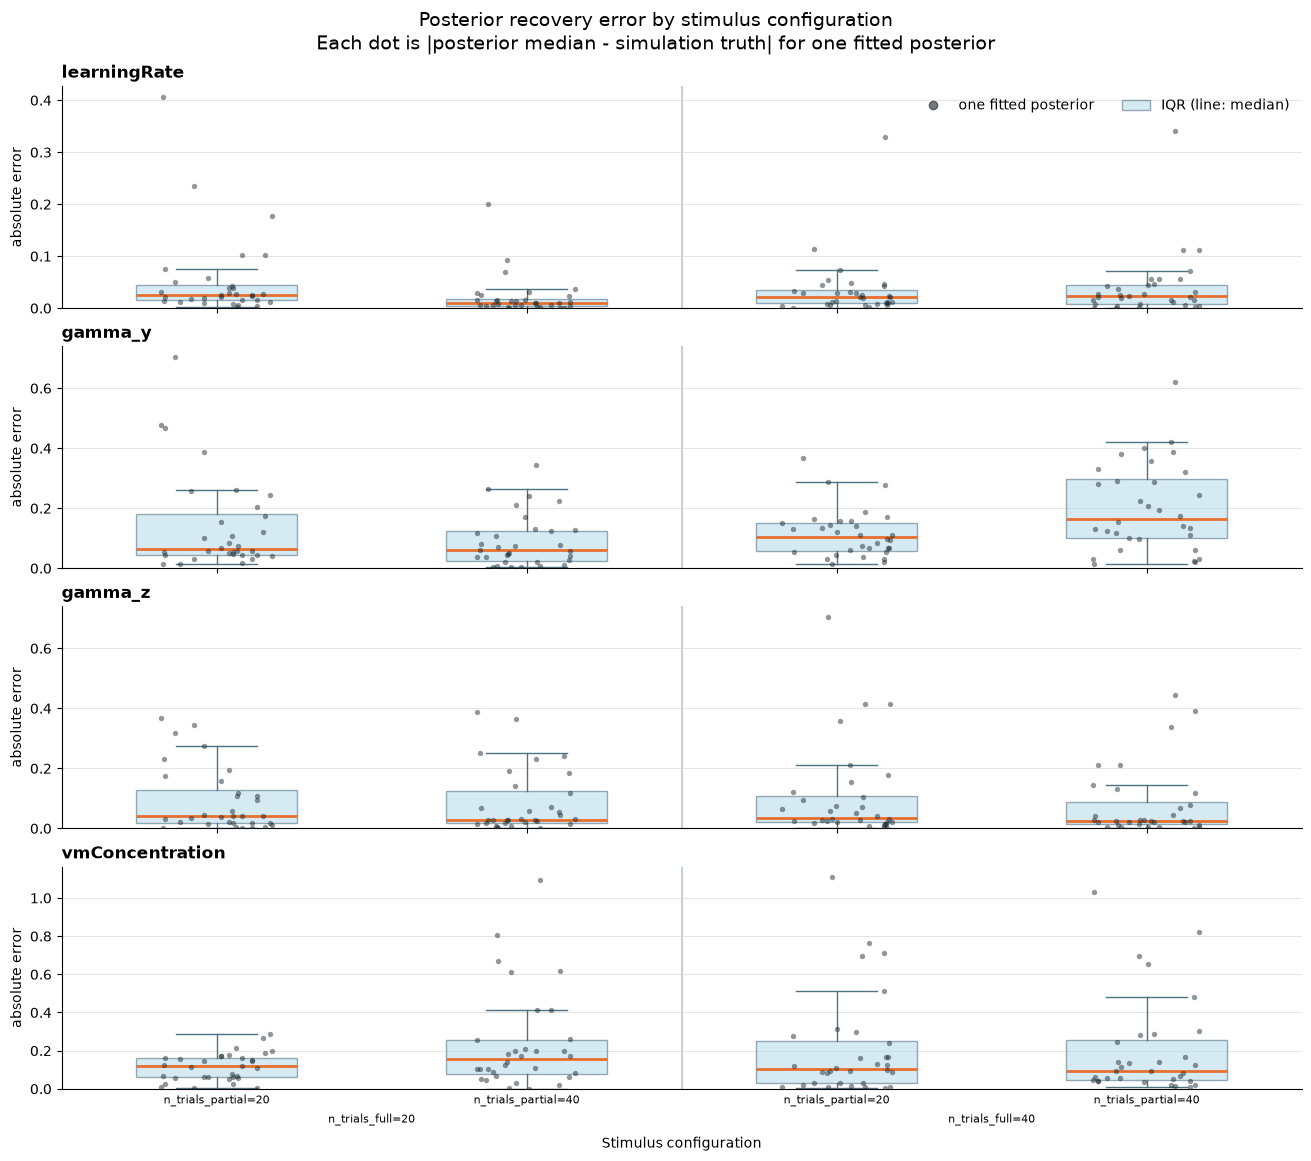

In [7]:
def plot_posterior_recovery_errors(
    sweep: xr.Dataset,
    posterior_summary: xr.Dataset,
    *,
    random_seed: int = 0,
    figure_size: tuple[float, float] = (13.0, 11.5),
) -> plt.Figure:
    parameter_names = sweep["parameter"].to_numpy()
    config_ids = np.unique(sweep["stimulus_config"])
    config_masks = [sweep["stimulus_config"] == config_id for config_id in config_ids]
    config_rows: list[dict[str, str]] = []
    for mask in config_masks:
        label = sweep["stimulus_label"].where(mask, drop=True).isel(job_id=0).item()
        config_rows.append(
            dict(part.split("=", maxsplit=1) for part in label.split(", "))
        )

    level_names = list(config_rows[0])
    level_values = [[row[name] for name in level_names] for row in config_rows]

    absolute_error = abs(posterior_summary["median"] - posterior_summary["truth"])
    rng = np.random.default_rng(random_seed)
    jitter = [rng.uniform(-0.18, 0.18, mask.sum().item()) for mask in config_masks]
    x_positions = np.arange(config_ids.size)

    fig, axes_grid = plt.subplots(
        len(parameter_names),
        1,
        figsize=figure_size,
        sharex=True,
        squeeze=False,
        constrained_layout=True,
    )
    axes = axes_grid[:, 0]
    box_color = "#b9dced"
    point_color = "#17242b"
    median_color = "#e76f2e"

    for ax, parameter in zip(axes, parameter_names):
        values_by_config: list[np.ndarray] = []
        for x_position, mask, x_jitter in zip(x_positions, config_masks, jitter):
            values = (
                absolute_error.sel(parameter=parameter)
                .where(mask, drop=True)
                .to_numpy()
            )
            finite = np.isfinite(values)
            values_by_config.append(values[finite])
            ax.scatter(
                x_position + x_jitter[finite],
                values[finite],
                s=15,
                color=point_color,
                alpha=0.48,
                linewidth=0,
                zorder=3,
            )

        ax.boxplot(
            values_by_config,
            positions=x_positions,
            widths=0.52,
            manage_ticks=False,
            patch_artist=True,
            showfliers=False,
            boxprops={"facecolor": box_color, "edgecolor": "#4f7182", "alpha": 0.58},
            medianprops={"color": median_color, "linewidth": 2.0},
            whiskerprops={"color": "#4f7182", "linewidth": 1.0},
            capprops={"color": "#4f7182", "linewidth": 1.0},
            zorder=2,
        )
        ax.set_title(parameter, loc="left", fontweight="bold")
        ax.set_ylabel("absolute error")
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color="#d8d8d8", linewidth=0.8, alpha=0.65)
        ax.spines[["top", "right"]].set_visible(False)

    for boundary in range(1, config_ids.size):
        changed_level = next(
            index
            for index, (left, right) in enumerate(
                zip(level_values[boundary - 1], level_values[boundary])
            )
            if left != right
        )
        if changed_level == len(level_names) - 1:
            continue
        for ax in axes:
            ax.axvline(
                boundary - 0.5,
                color="#81919a",
                linewidth=1.2 - 0.25 * changed_level,
                alpha=0.52,
                zorder=0,
            )

    axes[-1].set_xlim(-0.5, config_ids.size - 0.5)
    axes[-1].set_xticks(
        x_positions,
        labels=[f"{level_names[-1]}={values[-1]}" for values in level_values],
    )
    axes[-1].tick_params(axis="x", length=0, labelsize=8, pad=4)

    # Put inner factors closest to the data and center outer labels over their spans.
    for depth, level_index in enumerate(range(len(level_names) - 2, -1, -1), start=1):
        group_keys = [values[: level_index + 1] for values in level_values]
        group_starts = [0] + [
            index
            for index in range(1, len(group_keys))
            if group_keys[index] != group_keys[index - 1]
        ]
        group_ends = group_starts[1:] + [len(group_keys)]
        centers = [
            (start + end - 1) / 2 for start, end in zip(group_starts, group_ends)
        ]
        labels = [
            f"{level_names[level_index]}={level_values[start][level_index]}"
            for start in group_starts
        ]
        nested_axis = axes[-1].secondary_xaxis(location=-0.105 * depth)
        nested_axis.set_xticks(centers, labels=labels)
        nested_axis.tick_params(axis="x", length=0, labelsize=8, pad=1)
        nested_axis.spines["bottom"].set_visible(False)
    nested_axis.set_xlabel("Stimulus configuration", labelpad=8)

    axes[0].legend(
        handles=[
            Line2D(
                [],
                [],
                marker="o",
                linestyle="None",
                color=point_color,
                alpha=0.6,
                label="one fitted posterior",
            ),
            mpatches.Patch(
                facecolor=box_color,
                edgecolor="#4f7182",
                alpha=0.58,
                label="IQR (line: median)",
            ),
        ],
        frameon=False,
        loc="upper right",
        ncol=2,
    )
    fig.suptitle(
        "Posterior recovery error by stimulus configuration\n"
        "Each dot is |posterior median - simulation truth| for one fitted posterior",
        fontsize=14,
    )
    return fig


recovery_error_figure = plot_posterior_recovery_errors(sweep, posterior_summary)
recovery_error_figure;

### n_trials_full=20, n_trials_partial=20

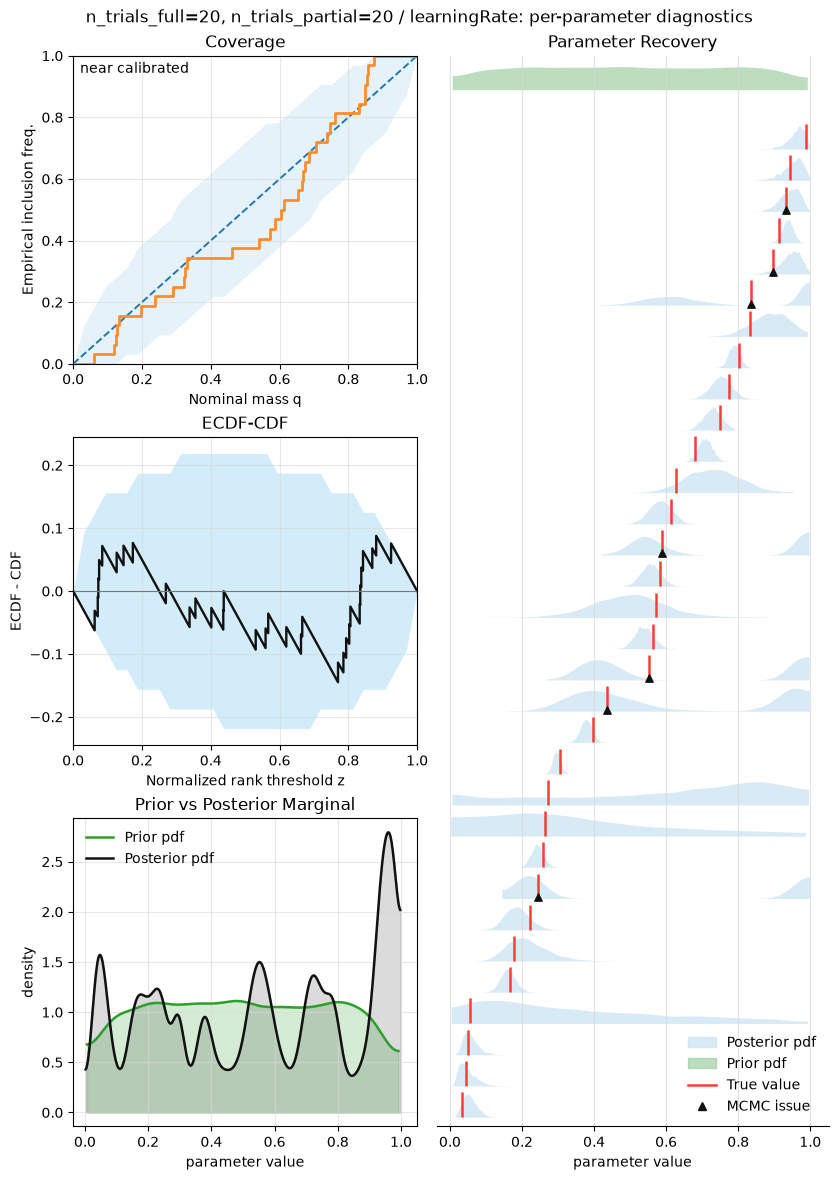

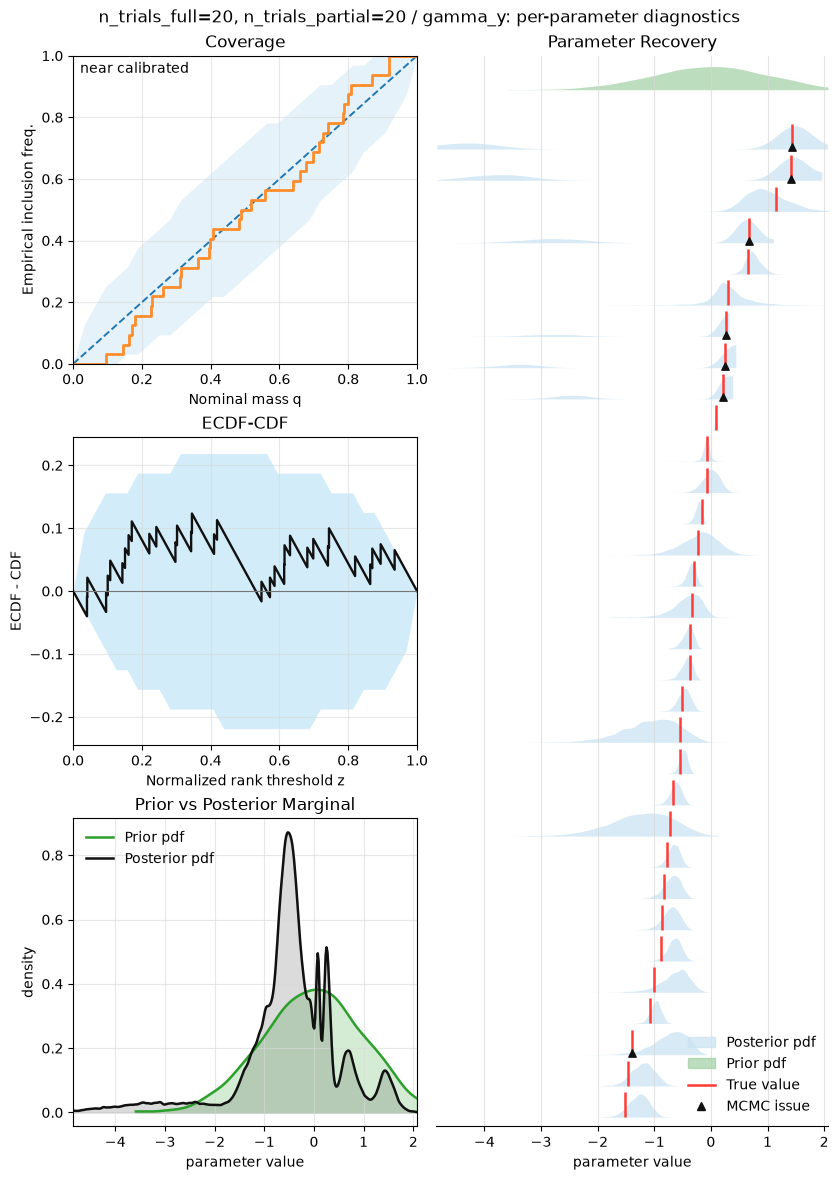

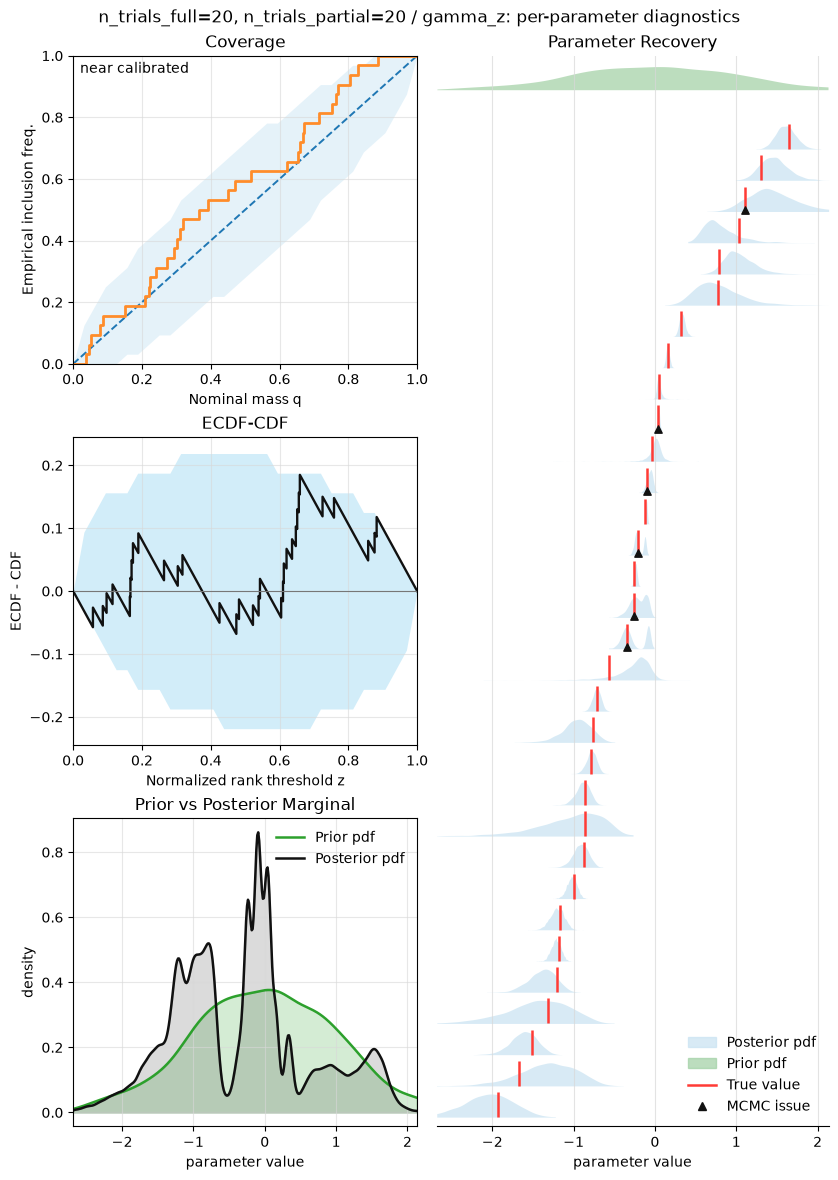

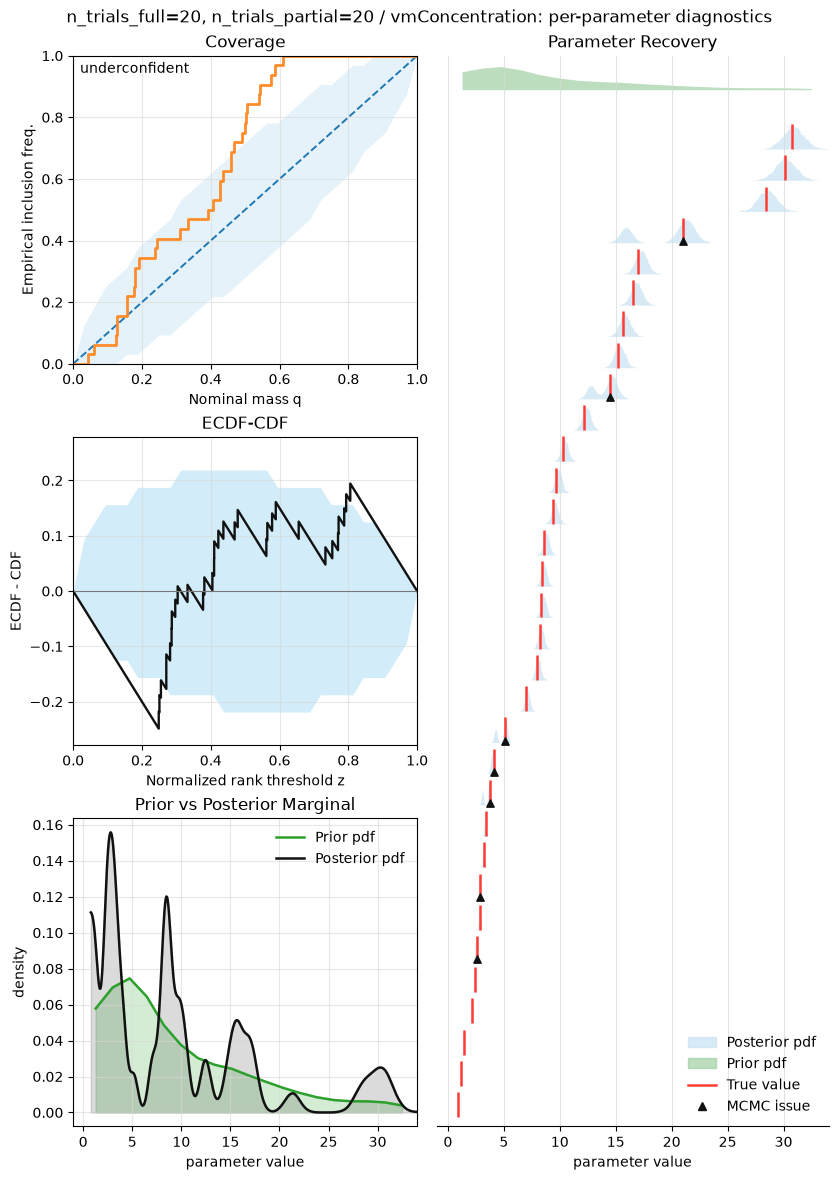

### n_trials_full=20, n_trials_partial=40

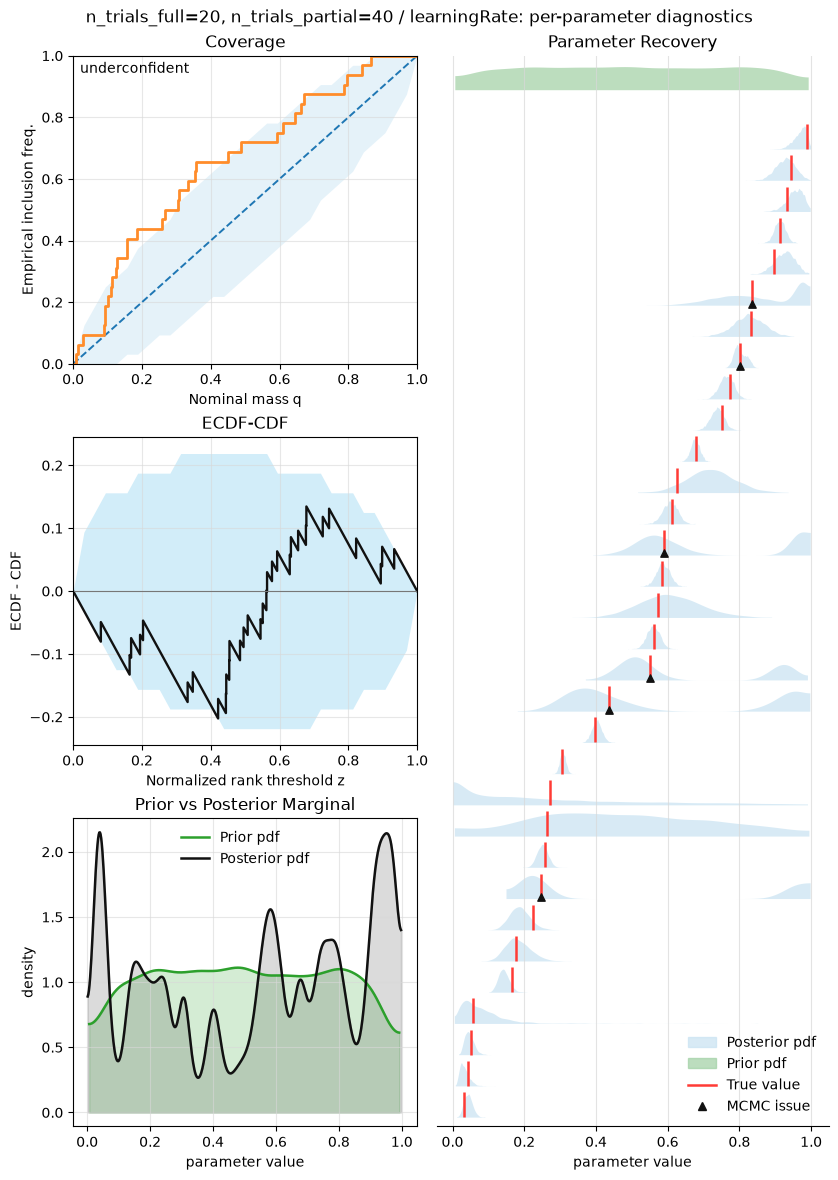

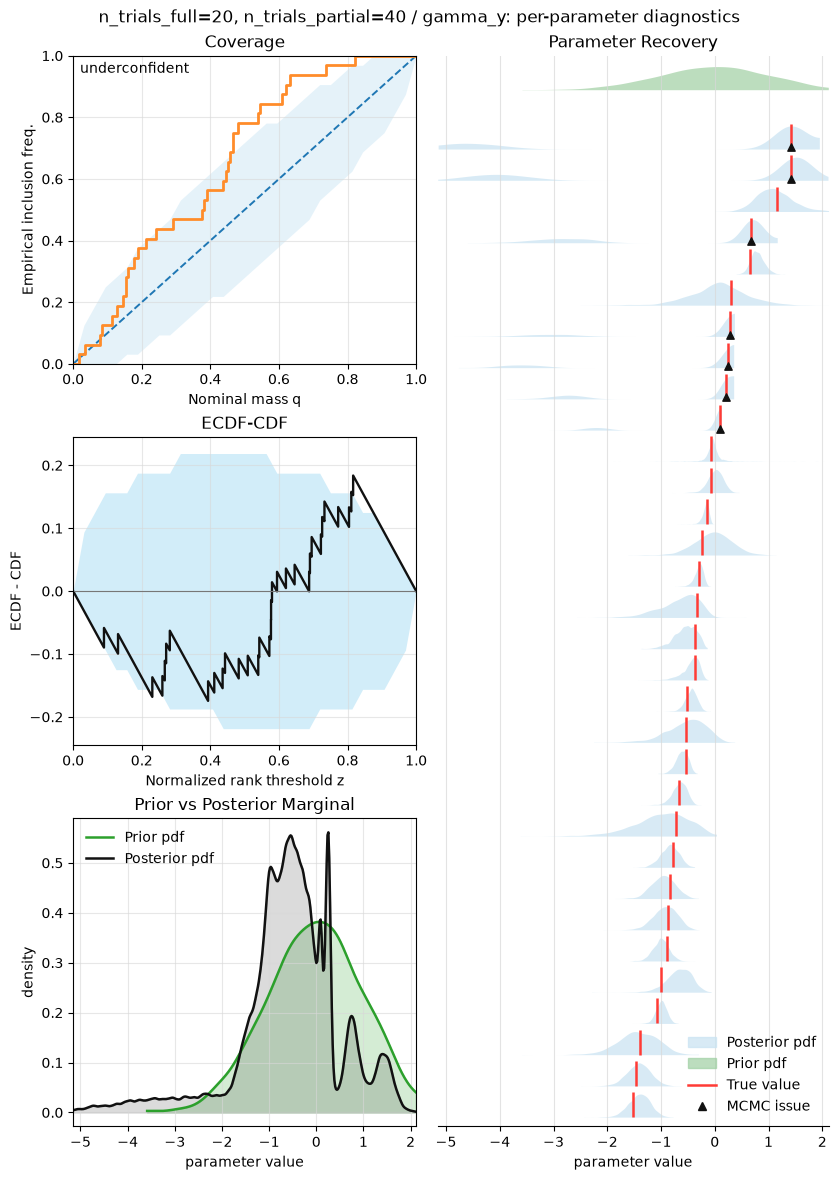

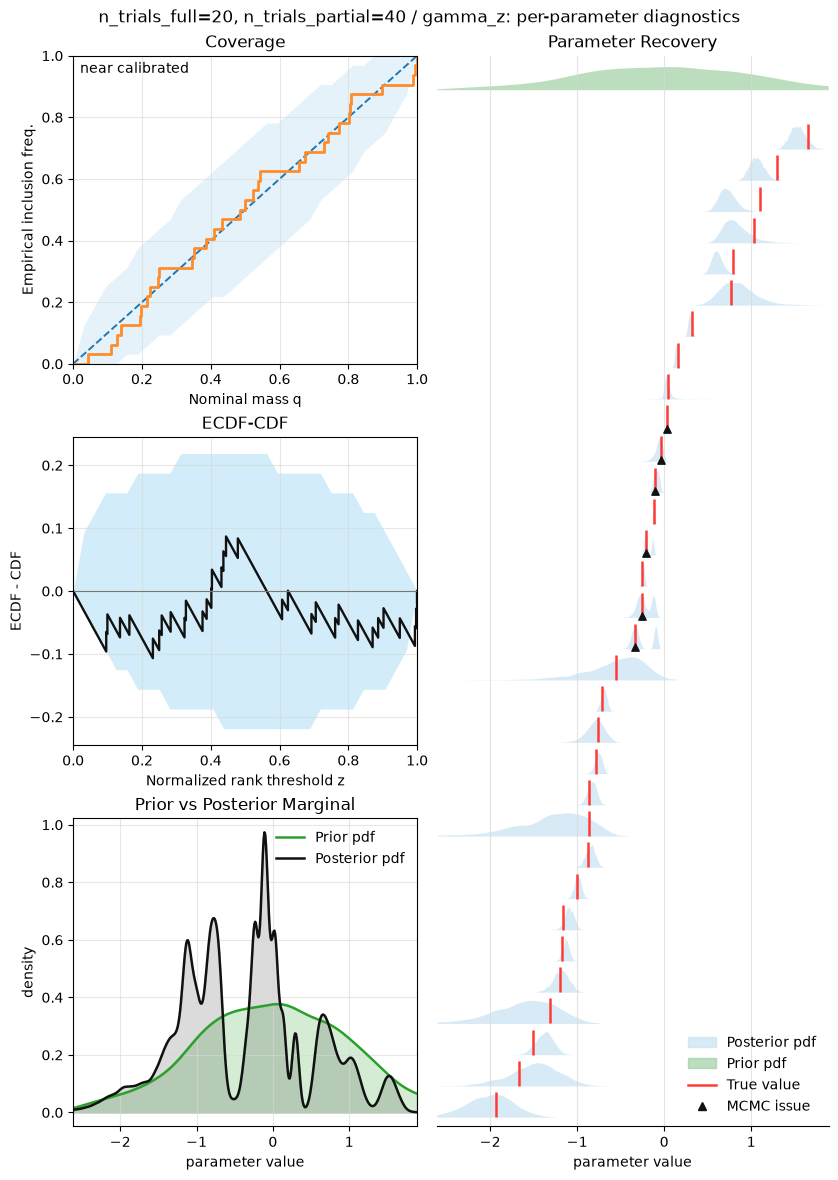

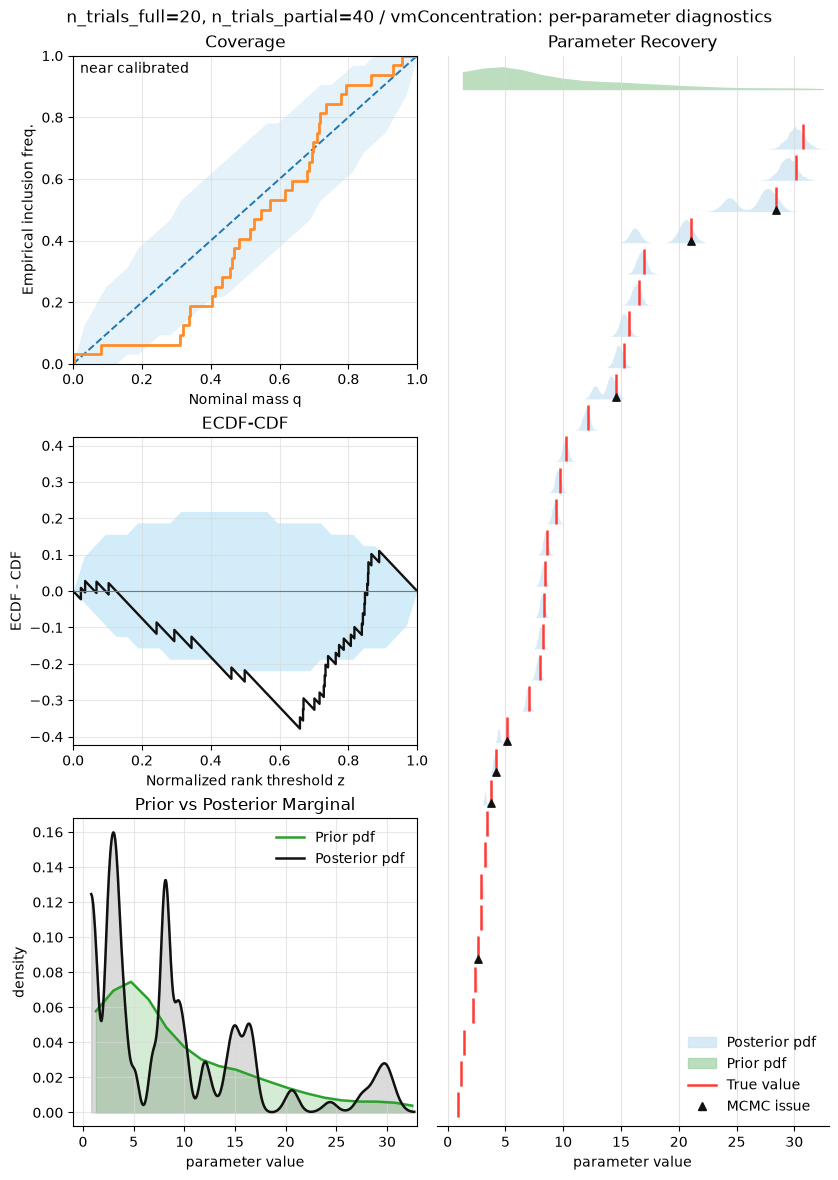

### n_trials_full=40, n_trials_partial=20

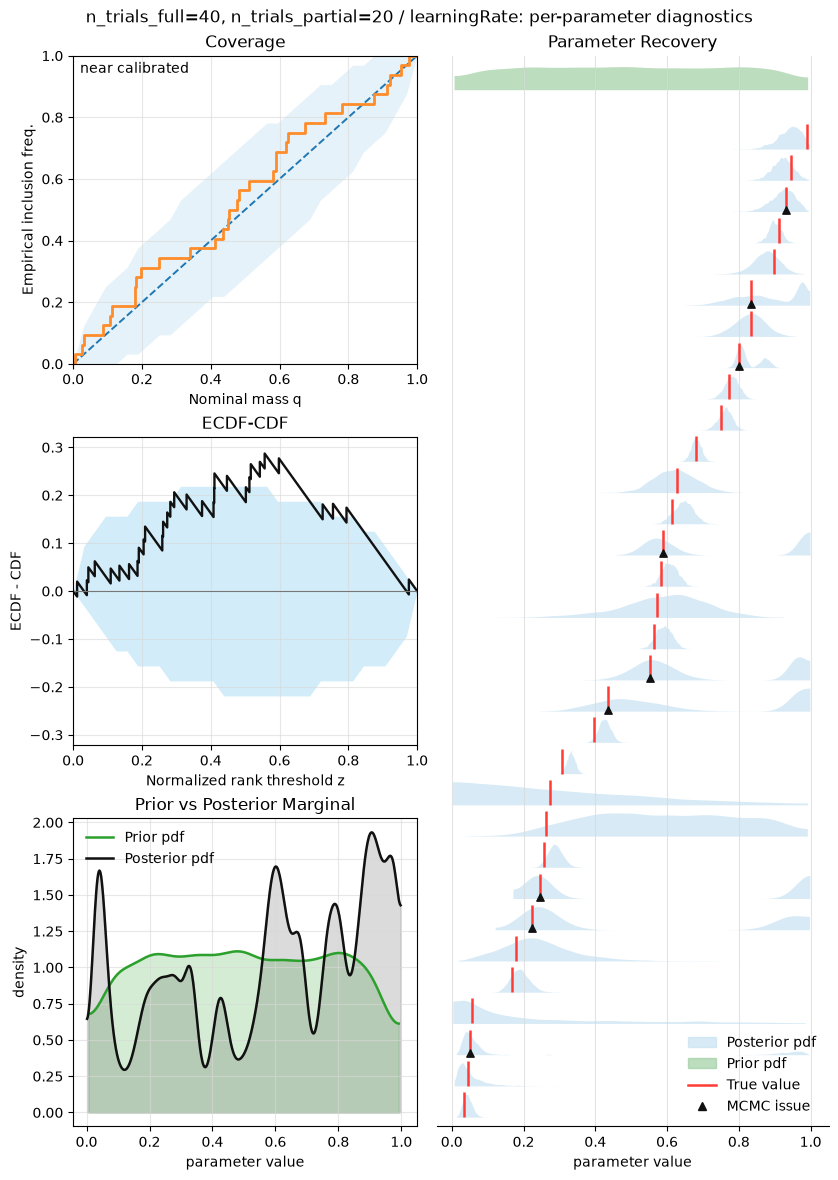

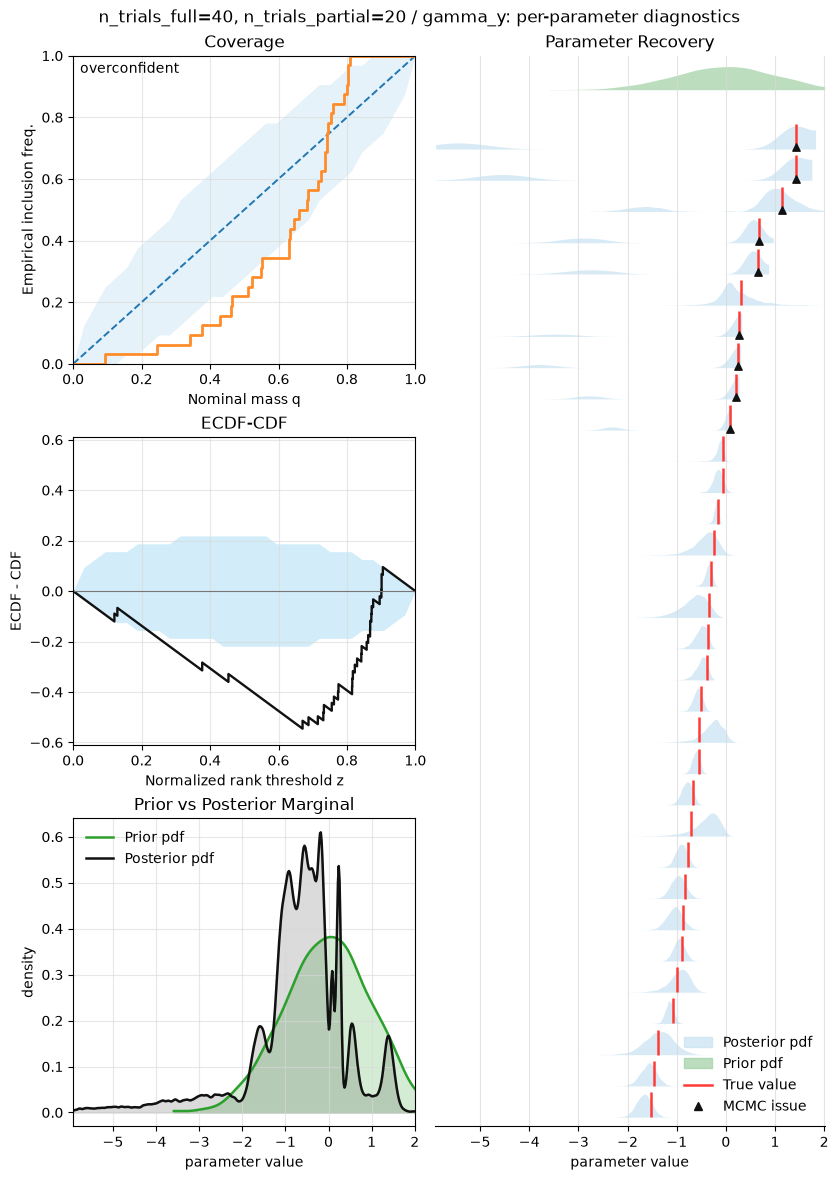

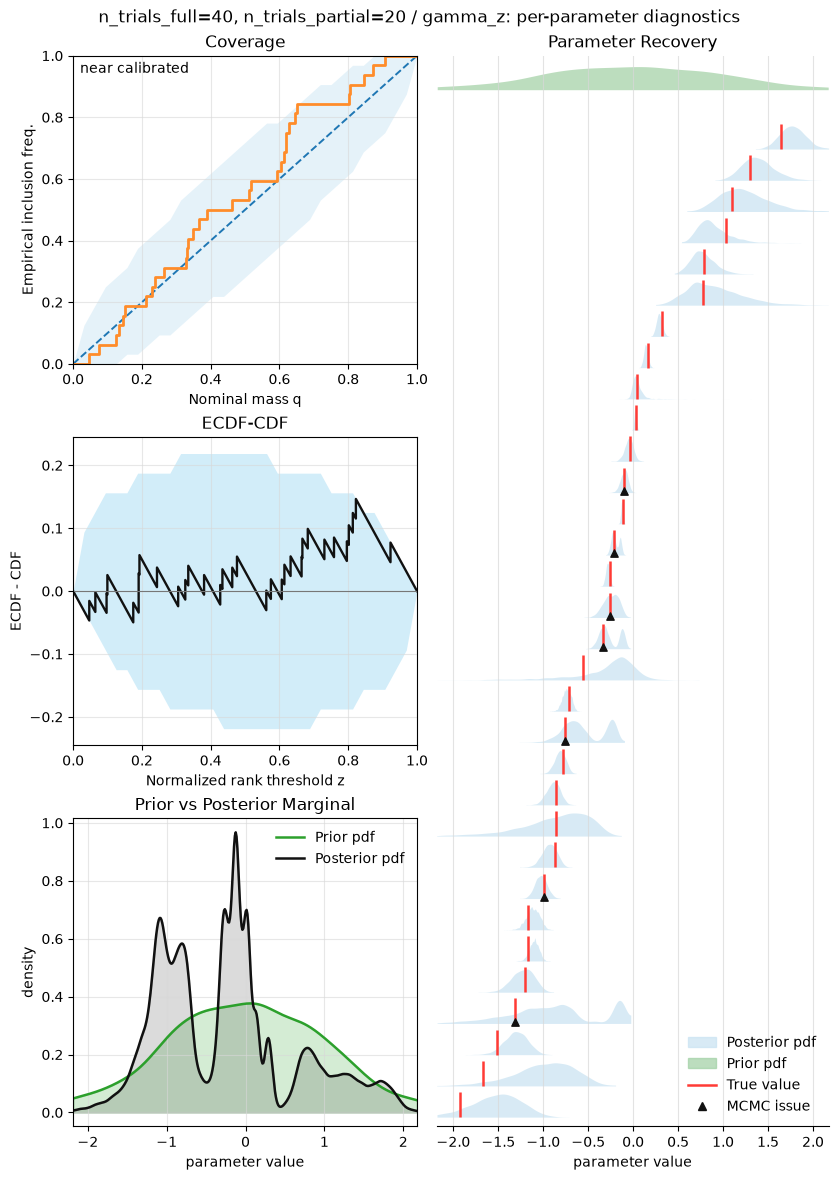

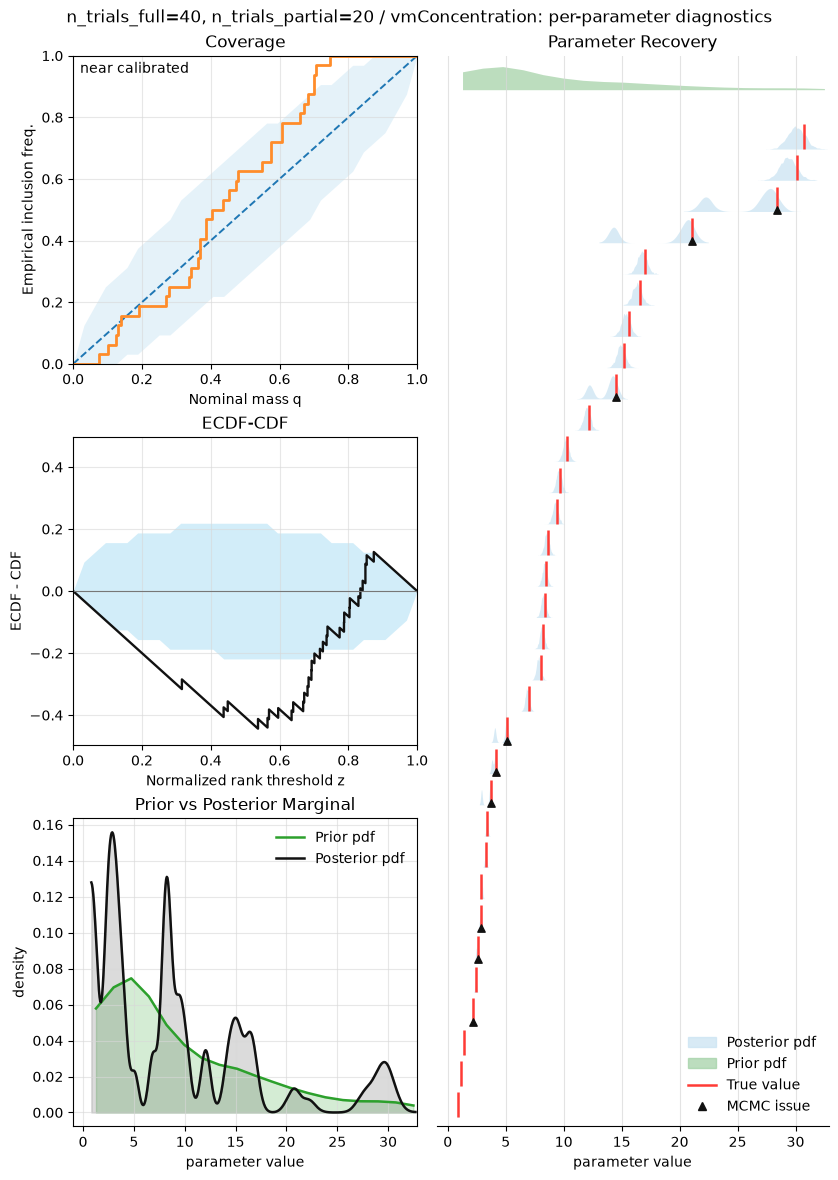

### n_trials_full=40, n_trials_partial=40

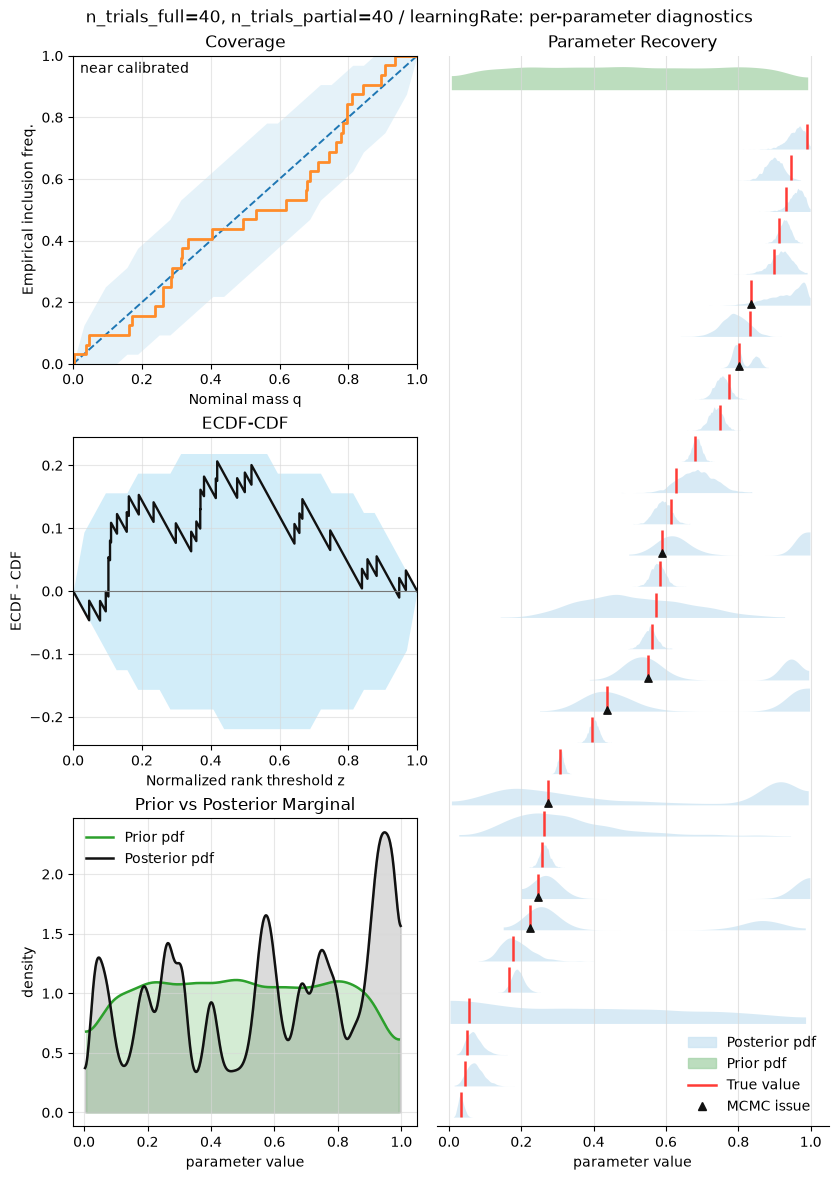

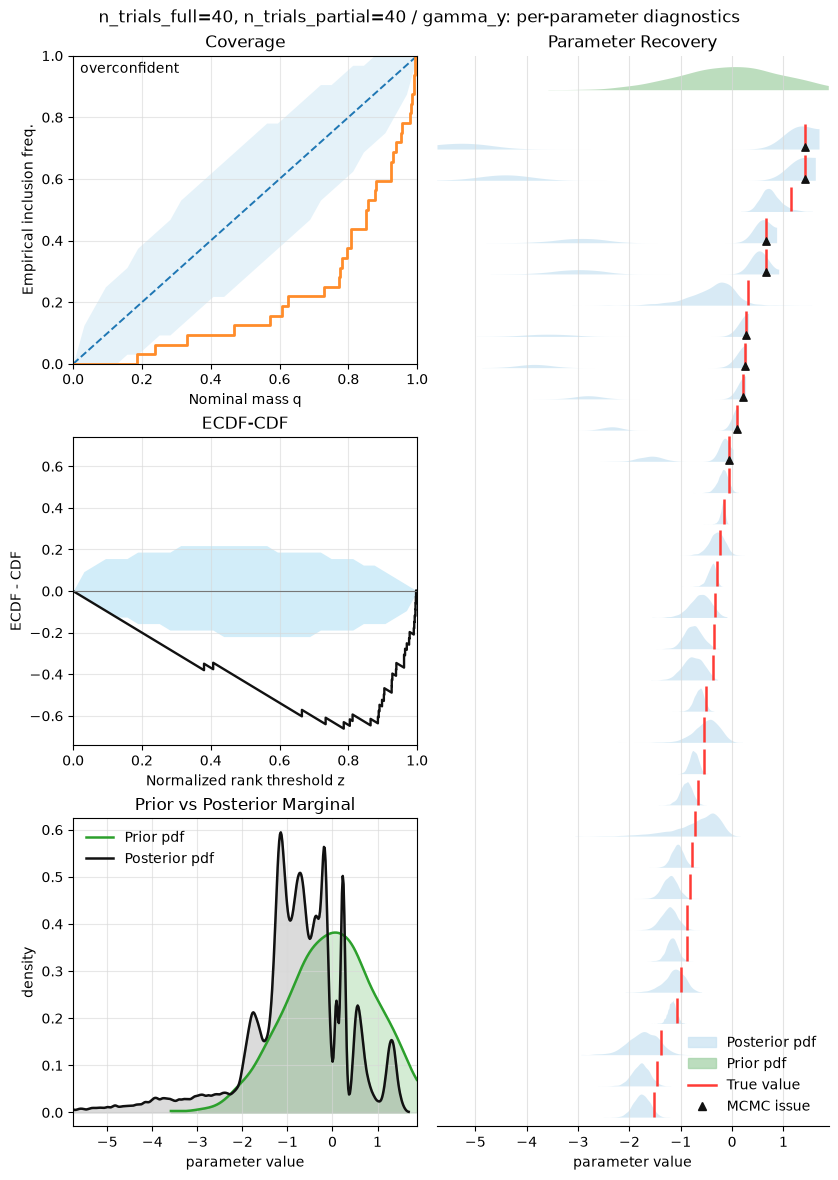

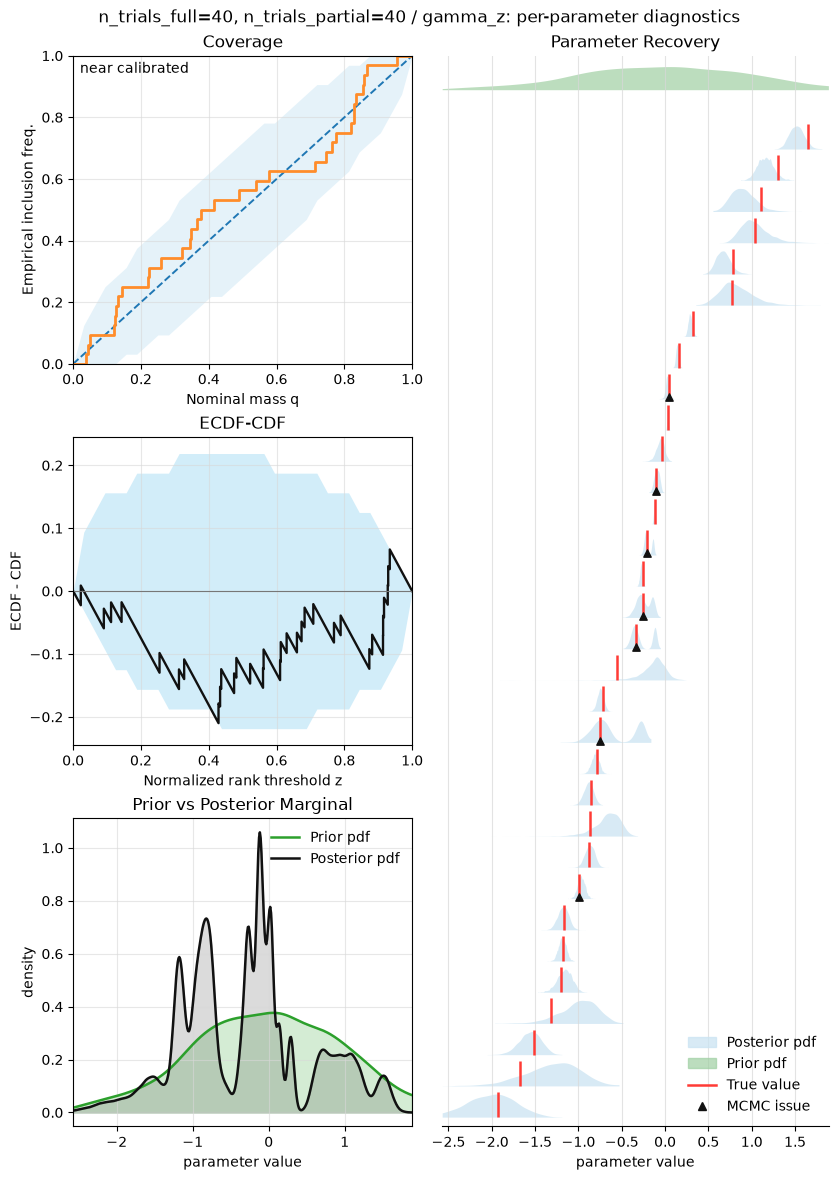

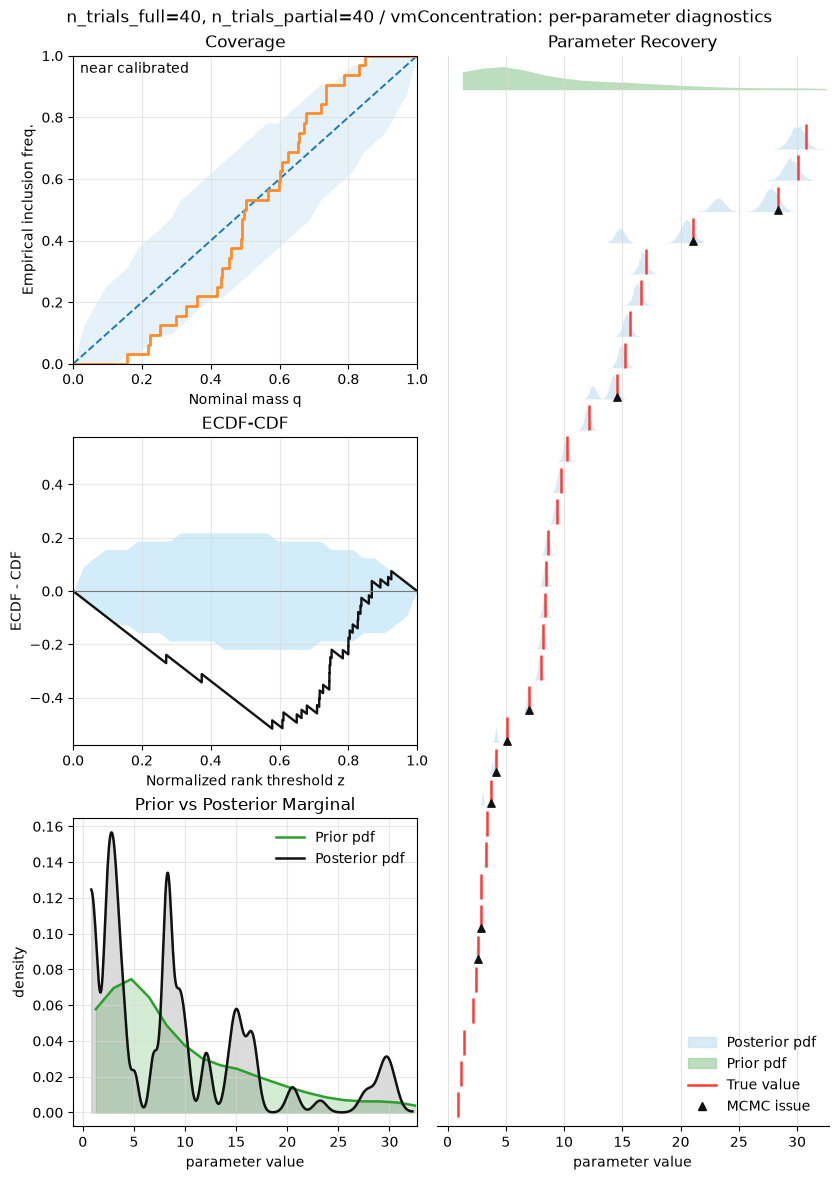

In [8]:
figures = plot_parameter_diagnostics_by_stimulus(sweep)

for label, parameter_figures in figures.items():
    display(Markdown(f"### {label}"))
    for figure in parameter_figures.values():
        display(figure)
        plt.close(figure)